# Interactive Well Deliverability & Tubing Sizing Simulator
### Nodal Analysis: IPR vs TPR


**Modeling note:** the TPR uses a homogeneous mixture density model +
Standing's black-oil correlations + a standard friction factor +
a Turner-critical-velocity liquid-loading correction, as a documented
simplification of the classical Poettmann-Carpenter chart-based method.


In [ ]:
!pip install -q numpy matplotlib scipy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import os
os.makedirs("outputs", exist_ok=True)

## 1. IPR module — Vogel's equation

In [ ]:
def vogel_ipr(pr: float, q_max: float, n_points: int = 50):
    """Generate the IPR curve using Vogel's equation."""
    pwf = np.linspace(pr, 0, n_points)
    ratio = pwf / pr
    q = q_max * (1 - 0.2 * ratio - 0.8 * ratio**2)
    return q, pwf


def vogel_pwf_from_q(pr: float, q_max: float, q):
    """Invert Vogel's equation to get pwf for a given array of rates q."""
    q = np.asarray(q, dtype=float)
    a, b = 0.8, 0.2
    c = -(1 - q / q_max)
    disc = np.clip(b**2 - 4 * a * c, 0, None)
    x = np.clip((-b + np.sqrt(disc)) / (2 * a), 0, 1)
    return x * pr

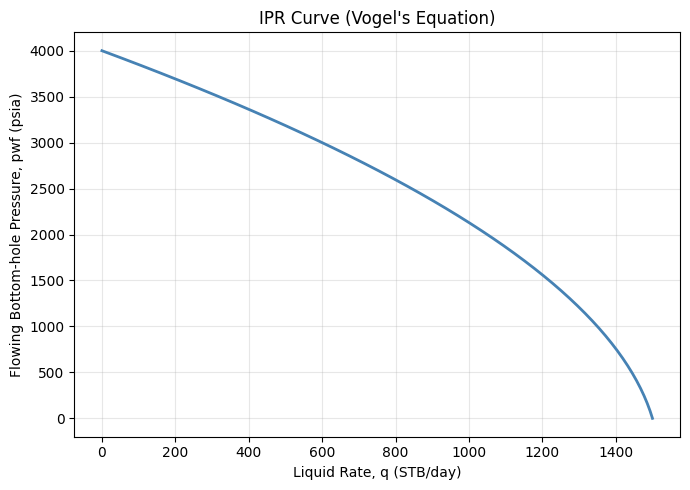

In [ ]:
# --- Example inputs (edit for your project) ---
PR = 4000       # reservoir pressure, psia
Q_MAX = 1500    # AOF, STB/day

q, pwf = vogel_ipr(PR, Q_MAX)

plt.figure(figsize=(7, 5))
plt.plot(q, pwf, lw=2, color="steelblue")
plt.xlabel("Liquid Rate, q (STB/day)")
plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
plt.title("IPR Curve (Vogel's Equation)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/ipr_curve.png", dpi=150)
plt.show()

## 2. TPR module — stepwise multiphase pressure traverse

**Simplification note:** the classical Poettmann-Carpenter method reads
its two-phase friction factor off an empirical field-data chart. This
uses a homogeneous (no-slip) mixture model with Standing's black-oil
correlations and a standard Moody friction factor.

In [ ]:
G = 32.174
GC = 32.174


def standing_rs(p, T, api, gas_sg):
    """Standing's correlation for solution GOR, scf/STB."""
    x = 0.0125 * api - 0.00091 * T
    rs = gas_sg * ((p / 18.2 + 1.4) * 10**x) ** 1.2048
    return max(rs, 0)


def standing_bo(rs, T, api, gas_sg, oil_sg):
    """Standing's correlation for oil formation volume factor, bbl/STB."""
    F = rs * (gas_sg / oil_sg) ** 0.5 + 1.25 * T
    return 0.9759 + 0.00012 * F**1.2


def mixture_density(p, T, api, gas_sg, water_cut, GOR, q_o_stb):
    """Approximate in-situ mixture (no-slip) density, lbm/ft3."""
    oil_sg = 141.5 / (131.5 + api)
    rs = min(standing_rs(p, T, api, gas_sg), GOR)
    bo = standing_bo(rs, T, api, gas_sg, oil_sg)

    rho_oil = (350.17 * oil_sg + 0.0764 * gas_sg * rs) / (5.615 * bo)
    rho_water = 62.4 * 1.07
    rho_liquid = (1 - water_cut) * rho_oil + water_cut * rho_water

    free_gor = max(GOR - rs, 0)
    z = 0.85
    R = 10.732
    Tr = T + 460
    Mg = 28.97 * gas_sg
    rho_gas = (p * Mg) / (z * R * Tr) if free_gor > 0 else 0

    liquid_vol = 5.615
    gas_vol = free_gor * (14.7 / p) * (Tr / 520) * (1 / z) if p > 0 else 0
    total_vol = liquid_vol + gas_vol
    lambda_l = liquid_vol / total_vol if total_vol > 0 else 1.0

    rho_mix = lambda_l * rho_liquid + (1 - lambda_l) * rho_gas
    return max(rho_mix, 1.0)


def friction_pressure_drop(rho, v, d_in, dh_ft, mu_cp=1.0):
    """Frictional pressure drop over a segment (Swamee-Jain), psi."""
    d_ft = d_in / 12
    mu = mu_cp * 6.72e-4

    Re = max((rho * v * d_ft) / mu if mu > 0 else 1e6, 1000)
    eps_d = 0.0006 / d_ft
    f_moody = 0.25 / (np.log10(eps_d / 3.7 + 5.74 / Re**0.9)) ** 2
    f_fanning = f_moody / 4

    return (2 * f_fanning * rho * v**2 * dh_ft) / (GC * d_ft) / 144


def tpr_pwf(q_liquid_stb, tubing_id_in, depth_ft, p_wh, T_wh, T_bh,
            water_cut, GOR, api, gas_sg, n_segments=10):
    """March down the tubing in n_segments to get pwf for one rate."""
    if q_liquid_stb <= 0:
        return p_wh

    dh = depth_ft / n_segments
    p = p_wh

    for i in range(n_segments):
        T = T_wh + (T_bh - T_wh) * (i + 0.5) / n_segments

        dp_guess = 5.0
        for _ in range(15):
            p_avg = p + dp_guess / 2
            rho = mixture_density(p_avg, T, api, gas_sg, water_cut, GOR, q_liquid_stb)

            q_ft3_s = q_liquid_stb * 5.615 / 86400
            area = np.pi / 4 * (tubing_id_in / 12) ** 2
            v = q_ft3_s / area

            # Liquid-loading correction (Turner critical velocity) --
            # produces the classic U-shaped TPR curve at low rates.
            oil_sg = 141.5 / (131.5 + api)
            rho_liquid_approx = 62.4 * (oil_sg * (1 - water_cut) + 1.07 * water_cut)
            sigma = 25
            rho_gas_approx = max(rho * 0.05, 0.05)
            v_crit = max(1.593 * (sigma * (rho_liquid_approx - rho_gas_approx)) ** 0.25
                         / rho_gas_approx ** 0.5 / 100, 1.0)

            if v < v_crit:
                loading_frac = min((v_crit - v) / v_crit, 1.0)
                rho = rho + 0.4 * loading_frac * (rho_liquid_approx - rho)

            dp_elevation = rho * dh / 144
            dp_friction = friction_pressure_drop(rho, v, tubing_id_in, dh)
            dp_guess = dp_elevation + dp_friction

        p += dp_guess

    return p


def tpr_curve(q_array, tubing_id_in, depth_ft, p_wh, T_wh, T_bh,
              water_cut, GOR, api, gas_sg, n_segments=10):
    """Vectorized wrapper: returns pwf for an array of liquid rates."""
    return np.array([
        tpr_pwf(q, tubing_id_in, depth_ft, p_wh, T_wh, T_bh,
                water_cut, GOR, api, gas_sg, n_segments)
        for q in q_array
    ])

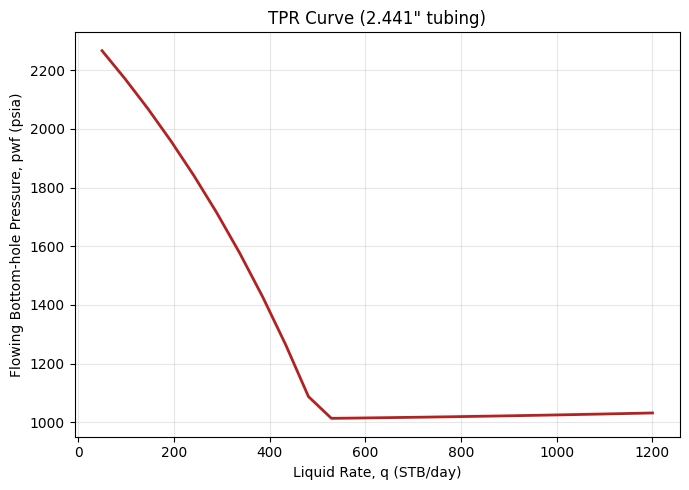

In [ ]:

Q = np.linspace(50, 1200, 25)
TUBING_ID = 2.441       # inches
DEPTH = 8000            # ft
P_WH = 200              # wellhead pressure, psia
T_WH, T_BH = 120, 180   # deg F
WATER_CUT = 0.1
GOR = 500                # scf/STB
API = 35
GAS_SG = 0.7

pwf_t = tpr_curve(Q, TUBING_ID, DEPTH, P_WH, T_WH, T_BH, WATER_CUT, GOR, API, GAS_SG)

plt.figure(figsize=(7, 5))
plt.plot(Q, pwf_t, lw=2, color="firebrick")
plt.xlabel("Liquid Rate, q (STB/day)")
plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
plt.title(f'TPR Curve ({TUBING_ID}" tubing)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/tpr_curve.png", dpi=150)
plt.show()

## 3. Nodal analysis — find the operating point

In [ ]:
def find_operating_point(pr, q_max, tubing_id_in, depth_ft, p_wh,
                          T_wh, T_bh, water_cut, GOR, api, gas_sg,
                          q_min=10, q_search_max=None, n_points=40):
    if q_search_max is None:
        q_search_max = q_max * 0.98

    q_array = np.linspace(q_min, q_search_max, n_points)
    pwf_ipr = vogel_pwf_from_q(pr, q_max, q_array)
    pwf_tpr = tpr_curve(q_array, tubing_id_in, depth_ft, p_wh, T_wh, T_bh,
                         water_cut, GOR, api, gas_sg)
    diff = pwf_ipr - pwf_tpr

    sign_changes = np.where(np.diff(np.sign(diff)) != 0)[0]
    if len(sign_changes) == 0:
        return None, None

    i = sign_changes[0]

    def f(q):
        p_ipr = vogel_pwf_from_q(pr, q_max, np.array([q]))[0]
        p_tpr = tpr_curve(np.array([q]), tubing_id_in, depth_ft, p_wh,
                           T_wh, T_bh, water_cut, GOR, api, gas_sg)[0]
        return p_ipr - p_tpr

    q_op = brentq(f, q_array[i], q_array[i + 1])
    pwf_op = vogel_pwf_from_q(pr, q_max, np.array([q_op]))[0]
    return q_op, pwf_op

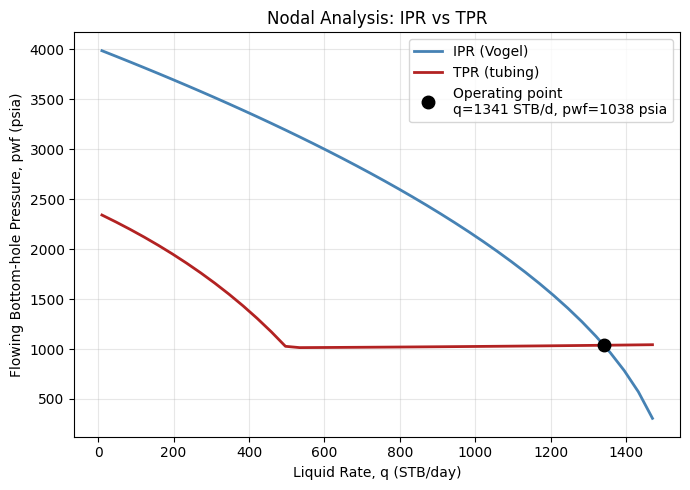

Operating point: q = 1341.4 STB/day, pwf = 1037.7 psia


In [ ]:
q_array = np.linspace(10, Q_MAX * 0.98, 40)
pwf_ipr = vogel_pwf_from_q(PR, Q_MAX, q_array)
pwf_tpr = tpr_curve(q_array, TUBING_ID, DEPTH, P_WH, T_WH, T_BH, WATER_CUT, GOR, API, GAS_SG)

q_op, pwf_op = find_operating_point(PR, Q_MAX, TUBING_ID, DEPTH, P_WH,
                                     T_WH, T_BH, WATER_CUT, GOR, API, GAS_SG)

plt.figure(figsize=(7, 5))
plt.plot(q_array, pwf_ipr, lw=2, color="steelblue", label="IPR (Vogel)")
plt.plot(q_array, pwf_tpr, lw=2, color="firebrick", label="TPR (tubing)")
if q_op is not None:
    plt.plot(q_op, pwf_op, "ko", ms=9,
              label=f"Operating point\nq={q_op:.0f} STB/d, pwf={pwf_op:.0f} psia")
plt.xlabel("Liquid Rate, q (STB/day)")
plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
plt.title("Nodal Analysis: IPR vs TPR")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/nodal_plot.png", dpi=150)
plt.show()

print(f"Operating point: q = {q_op:.1f} STB/day, pwf = {pwf_op:.1f} psia")

## Tubing size and water cut

In [ ]:
# --- Base case (reused from above) ---
Q_ARRAY = np.linspace(10, Q_MAX * 0.98, 40)

def tubing_size_sensitivity(water_cut=0.1):
    tubing_sizes = [1.995, 2.441, 2.992]
    colors = ["#4C72B0", "#DD8452", "#55A868"]

    plt.figure(figsize=(7.5, 5.5))
    pwf_ipr = vogel_pwf_from_q(PR, Q_MAX, Q_ARRAY)
    plt.plot(Q_ARRAY, pwf_ipr, lw=2.5, color="black", label="IPR")

    print("--- Tubing Size Sensitivity ---")
    for d, c in zip(tubing_sizes, colors):
        pwf_t = tpr_curve(Q_ARRAY, d, DEPTH, P_WH, T_WH, T_BH, water_cut, GOR, API, GAS_SG)
        plt.plot(Q_ARRAY, pwf_t, lw=2, color=c, label=f'{d}" tubing')

        q_o, pwf_o = find_operating_point(PR, Q_MAX, d, DEPTH, P_WH, T_WH, T_BH,
                                           water_cut, GOR, API, GAS_SG)
        if q_o:
            plt.plot(q_o, pwf_o, "o", color=c, ms=8)
            print(f'  {d}" tubing -> q = {q_o:.0f} STB/day, pwf = {pwf_o:.0f} psia')

    plt.xlabel("Liquid Rate, q (STB/day)")
    plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
    plt.title("Sensitivity: Tubing Size")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("outputs/sensitivity_tubing_size.png", dpi=150)
    plt.show()


def water_cut_sensitivity(tubing_id=2.441):
    water_cuts = [0.0, 0.2, 0.35, 0.5]
    colors = ["#4C72B0", "#DD8452", "#C44E52", "#8172B2"]

    plt.figure(figsize=(7.5, 5.5))
    pwf_ipr = vogel_pwf_from_q(PR, Q_MAX, Q_ARRAY)
    plt.plot(Q_ARRAY, pwf_ipr, lw=2.5, color="black", label="IPR")

    print("--- Water Cut Sensitivity ---")
    for wc, c in zip(water_cuts, colors):
        pwf_t = tpr_curve(Q_ARRAY, tubing_id, DEPTH, P_WH, T_WH, T_BH, wc, GOR, API, GAS_SG)
        plt.plot(Q_ARRAY, pwf_t, lw=2, color=c, label=f"WC = {int(wc*100)}%")

        q_o, pwf_o = find_operating_point(PR, Q_MAX, tubing_id, DEPTH, P_WH, T_WH, T_BH,
                                           wc, GOR, API, GAS_SG)
        if q_o:
            plt.plot(q_o, pwf_o, "o", color=c, ms=8)
            print(f"  WC = {int(wc*100)}% -> q = {q_o:.0f} STB/day, pwf = {pwf_o:.0f} psia")

    plt.xlabel("Liquid Rate, q (STB/day)")
    plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
    plt.title("Sensitivity: Water Cut")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("outputs/sensitivity_water_cut.png", dpi=150)
    plt.show()

--- Tubing Size Sensitivity ---
  1.995" tubing -> q = 1330 STB/day, pwf = 1088 psia
  2.441" tubing -> q = 1341 STB/day, pwf = 1038 psia
  2.992" tubing -> q = 1346 STB/day, pwf = 1019 psia


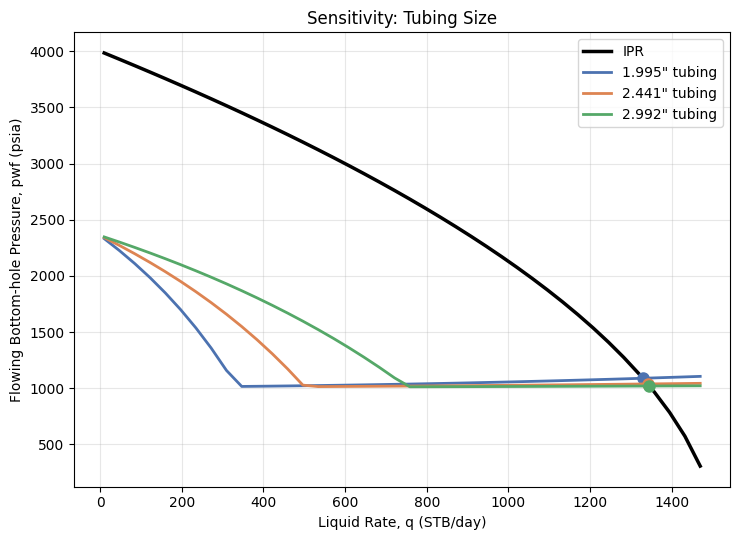

In [ ]:
tubing_size_sensitivity()

--- Water Cut Sensitivity ---
  WC = 0% -> q = 1351 STB/day, pwf = 993 psia
  WC = 20% -> q = 1331 STB/day, pwf = 1084 psia
  WC = 35% -> q = 1313 STB/day, pwf = 1157 psia
  WC = 50% -> q = 1293 STB/day, pwf = 1235 psia


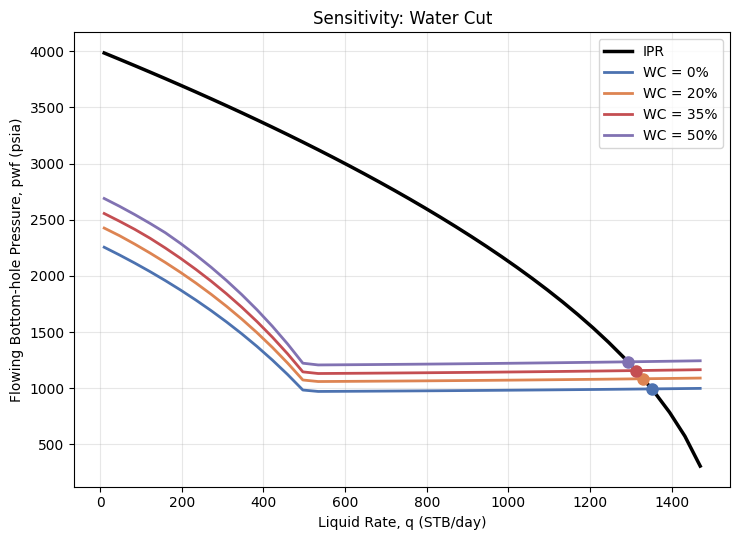

In [ ]:
water_cut_sensitivity()

## 5. Interactive: Water Cut vs IPR

The static plots above are useful for a report, but for exploring the model it helps to move sliders and see the curves redraw immediately.

This cell overlays the TPR curve for **several water cuts at once against the IPR
curve**, and lets you pick which water cuts to show, plus adjust the main reservoir/
tubing inputs — all with widgets, no re-running cells needed.



In [ ]:
!pip install -q ipywidgets

In [ ]:
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, Dropdown, SelectMultiple, fixed

WC_OPTIONS = [("0%", 0.0), ("10%", 0.1), ("20%", 0.2), ("30%", 0.3),
              ("40%", 0.4), ("50%", 0.5), ("60%", 0.6), ("70%", 0.7)]

TUBING_OPTIONS = [1.995, 2.441, 2.992, 3.5]

_COLORS = ["#4C72B0", "#DD8452", "#C44E52", "#8172B2", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974"]


def _interactive_water_cut_vs_ipr(pr, q_max, tubing_id, depth, p_wh, gor, api, gas_sg, water_cuts):
    if not water_cuts:
        print("Select at least one water cut above.")
        return

    q_array = np.linspace(10, q_max * 0.98, 40)
    pwf_ipr = vogel_pwf_from_q(pr, q_max, q_array)

    plt.figure(figsize=(7.5, 5.5))
    plt.plot(q_array, pwf_ipr, lw=2.5, color="black", label="IPR")

    for wc, c in zip(water_cuts, _COLORS):
        pwf_t = tpr_curve(q_array, tubing_id, depth, p_wh, T_WH, T_BH, wc, gor, api, gas_sg)
        plt.plot(q_array, pwf_t, lw=2, color=c, label=f"TPR, WC = {int(wc * 100)}%")

        q_o, pwf_o = find_operating_point(pr, q_max, tubing_id, depth, p_wh,
                                           T_WH, T_BH, wc, gor, api, gas_sg)
        if q_o is not None:
            plt.plot(q_o, pwf_o, "o", color=c, ms=8)
            print(f"  WC = {int(wc * 100):>3}%  ->  q = {q_o:6.0f} STB/day   pwf = {pwf_o:6.0f} psia")

    plt.xlabel("Liquid Rate, q (STB/day)")
    plt.ylabel("Flowing Bottom-hole Pressure, pwf (psia)")
    plt.title(f'Water Cut vs IPR  ({tubing_id}" tubing, depth {depth:.0f} ft)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


interact(
    _interactive_water_cut_vs_ipr,
    pr=FloatSlider(value=PR, min=1500, max=6000, step=100, description="Pr (psia)", continuous_update=False),
    q_max=FloatSlider(value=Q_MAX, min=200, max=2500, step=50, description="Qmax (STB/d)", continuous_update=False),
    tubing_id=Dropdown(options=TUBING_OPTIONS, value=TUBING_ID, description="Tubing ID"),
    depth=FloatSlider(value=DEPTH, min=2000, max=12000, step=250, description="Depth (ft)", continuous_update=False),
    p_wh=FloatSlider(value=P_WH, min=50, max=800, step=25, description="Pwh (psia)", continuous_update=False),
    gor=FloatSlider(value=GOR, min=100, max=2000, step=50, description="GOR (scf/STB)", continuous_update=False),
    api=FloatSlider(value=API, min=15, max=50, step=1, description="API", continuous_update=False),
    gas_sg=FloatSlider(value=GAS_SG, min=0.55, max=0.9, step=0.01, description="Gas SG", continuous_update=False),
    water_cuts=SelectMultiple(options=WC_OPTIONS, value=(0.0, 0.2, 0.4), description="Water cuts",
                               rows=len(WC_OPTIONS)),
);

interactive(children=(FloatSlider(value=4000.0, continuous_update=False, description='Pr (psia)', max=6000.0, …